# FloodNet Track 1 — YOLO11n-seg sobre la misma partición

Cuaderno de comparación. Entrena **YOLO11n-seg** (Ultralytics) con exactamente las mismas 317 / 40 / 41
imágenes de train / val / test que el U-Net híbrido de `floodnet-segmentation.ipynb`. Lo evalúa con
la misma métrica semántica (mIoU por acumulación de matriz de confusión) y deja el modelo exportado a
**ONNX** para medir después la inferencia en el mismo equipo.

## El problema de fondo: FloodNet no es un dataset de instancias

YOLO-seg es un modelo de **segmentación de instancias**: detecta objetos (caja + clase) y da una
máscara por objeto. FloodNet Track 1 es **segmentación semántica**: cada píxel tiene una clase y
no hay objetos. Hierba, árboles, agua y carreteras son *regiones*, no cosas contables.

Para poder entrenar YOLO se hace lo único razonable: **cada componente conexa de cada clase se
trata como una instancia** y su contorno se convierte en polígono. Eso tiene consecuencias que el
cuaderno mide en vez de suponer:

| Aspecto | Efecto |
|---|---|
| Clases *objeto* (edificios, vehículos, piscinas) | Encajan bien: regiones compactas y separadas. |
| Clases *región* (Grass, Tree, Road, Water) | Encajan mal: regiones enormes, con huecos y fragmentadas. |
| Huecos | Un polígono YOLO no tiene huecos. Se resuelve por orden de pintado (sección 3). |
| Resolución de máscara | YOLO predice prototipos a 1/4 (128×128 para 512): bordes más bastos. |
| Salida | Instancias, no un mapa por píxel. Hay que **repintarlas** en un mapa semántico, y los píxeles sin detección quedan sin clase (*void*). |

## Índice

| Sección | Contenido |
|---|---|
| **P** | Parámetros del experimento (todo lo configurable, en un sitio) |
| **0** | Entorno |
| **1** | Datos y partición (idéntica al cuaderno principal) |
| **2** | ¿Cuántas "instancias" hay? Análisis de componentes conexas |
| **3** | Conversión máscara → polígonos YOLO |
| **4** | Prueba de ida y vuelta: el techo que impone la conversión |
| **5** | Entrenamiento |
| **6** | Evaluación: mAP de instancias y mIoU semántico |
| **7** | Exportación a ONNX y verificación |

---
# P. Parámetros del experimento

**Todas las decisiones configurables están en esta celda.** Se imprimen aquí y se guardan, junto con
la lista de imágenes de cada partición y los resultados, en `models/yolo11n_seg_floodnet_config.json`,
al lado del `.onnx`. Así cualquier cifra del cuaderno se puede rastrear y replicar.

Sobre la resolución: **se entrena a 512×512**, la misma entrada que el U-Net híbrido. Se reutiliza
la caché `data/cache512` y la comparación es de igual a igual. Una resolución mayor favorecería a
*Vehicle* y a las máscaras a 1/4 de YOLO, pero obligaría a regenerar la caché y la comparación
dejaría de ser directa.

In [1]:
import json
import os
import random
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

CONFIG = {
    "experimento": "yolo11n-seg_floodnet_512",
    # --- datos y partición (idénticos a floodnet-segmentation.ipynb) ---
    "img_size": 512,                    # entrada del modelo = tamaño de la caché
    "seed": 42,                         # split (train_test_split) y entrenamiento
    "split": {
        "train": "data_finally/train completo (317)",
        "val":   "50 % de data_finally/val, estratificado por categoría (40)",
        "test":  "el otro 50 % de data_finally/val (41)",
    },
    # --- conversión máscara -> polígonos (sección 3) ---
    "min_area_px": 20,                  # componentes más pequeñas se descartan (ruido de anotación)
    "poly_eps_px": 1.0,                 # tolerancia de cv2.approxPolyDP
    # --- entrenamiento (Ultralytics) ---
    "modelo_base": "yolo11n-seg.pt",    # preentrenado en COCO
    "epochs": 300,                      # ~3 s/época en una RTX 4060 Laptop
    "patience": 100,                    # early stopping sobre fitness de val
    "batch": 16,
    "workers": 4,                       # con 0 cada época tarda ~6 veces más; si se cuelga en Windows, pon 0
    "optimizer": "auto",
    "fliplr": 0.5,
    "flipud": 0.5,                      # vista cenital: arriba/abajo es tan válido como izq/der
    "mosaic": 1.0,
    "overlap_mask": True,               # máscaras pintadas de mayor a menor área (ver sección 3)
    "deterministic": True,
    # --- inferencia y evaluación semántica (sección 6) ---
    "conf_candidatos": [0.05, 0.1, 0.25, 0.4],   # se elige en val, se aplica una vez en test
    "iou_nms": 0.7,
    "max_det": 300,
    "regla_repintado": "instancias de mayor a menor área; las pequeñas quedan encima; sin cubrir = void",
    # --- exportación ---
    "onnx_opset": 17,
    "onnx_path": "models/yolo11n_seg_floodnet.onnx",
    "config_json": "models/yolo11n_seg_floodnet_config.json",
}

# Poner ENTRENAR = False reutiliza el best.pt de una ejecución anterior.
ENTRENAR = True

random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])

print(json.dumps(CONFIG, indent=2, ensure_ascii=False))

{
  "experimento": "yolo11n-seg_floodnet_512",
  "img_size": 512,
  "seed": 42,
  "split": {
    "train": "data_finally/train completo (317)",
    "val": "50 % de data_finally/val, estratificado por categoría (40)",
    "test": "el otro 50 % de data_finally/val (41)"
  },
  "min_area_px": 20,
  "poly_eps_px": 1.0,
  "modelo_base": "yolo11n-seg.pt",
  "epochs": 300,
  "patience": 100,
  "batch": 16,
  "workers": 4,
  "optimizer": "auto",
  "fliplr": 0.5,
  "flipud": 0.5,
  "mosaic": 1.0,
  "overlap_mask": true,
  "deterministic": true,
  "conf_candidatos": [
    0.05,
    0.1,
    0.25,
    0.4
  ],
  "iou_nms": 0.7,
  "max_det": 300,
  "regla_repintado": "instancias de mayor a menor área; las pequeñas quedan encima; sin cubrir = void",
  "onnx_opset": 17,
  "onnx_path": "models/yolo11n_seg_floodnet.onnx",
  "config_json": "models/yolo11n_seg_floodnet_config.json"
}


---
# 0. Entorno

Se usa el mismo entorno `uv` que el cuaderno principal. Si es la primera vez, desde la raíz del
proyecto:

```bash
uv sync
uv run python -m ipykernel install --user --name floodnet --display-name "FloodNet (Python 3.12)"
```

y selecciona el kernel **FloodNet (Python 3.12)**. `pyproject.toml` ya incluye `ultralytics`,
`segmentation-models-pytorch`, `onnx`, `onnxscript`, `onnxslim` y `onnxruntime-gpu`.

`onnxruntime-gpu` está fijado a la 1.24: las ruedas más recientes de PyPI están compiladas contra
CUDA 13 y no cargan junto a PyTorch cu126.

In [2]:
import sys
import torch

print("Python  :", sys.version.split()[0], "-", sys.executable)
print("PyTorch :", torch.__version__, "| CUDA build:", torch.version.cuda)
assert torch.cuda.is_available(), "Sin GPU: el entrenamiento sería inviable."
print("GPU     :", torch.cuda.get_device_name(0))

import ultralytics
print("Ultralytics:", ultralytics.__version__)

Python  : 3.12.10 - c:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\.venv\Scripts\python.exe
PyTorch : 2.14.0+cu126 | CUDA build: 12.6
GPU     : NVIDIA GeForce RTX 4060 Laptop GPU
Ultralytics: 8.4.177


---
# 1. Datos y partición

Esta sección reproduce **exactamente** las secciones 1.1, 1.3 y 1.4 de
`floodnet-segmentation.ipynb`, para que el modelo se entrene y se evalúe sobre las mismas imágenes
que el U-Net híbrido:

| Partición | Origen | Imágenes |
|---|---|---:|
| train | `data_finally/train` | 317 |
| val | mitad de `data_finally/val`, estratificada por categoría (`SEED = 42`) | 40 |
| test | la otra mitad | 41 |

Si `data/cache512` ya existe (lo genera el cuaderno principal) se reutiliza; si no, se construye
aquí con el mismo código: imagen reducida con `INTER_AREA`, máscara con `INTER_NEAREST`.

### 1.1 Rutas y mapa de clases

In [3]:
PROJECT = Path.cwd()
DATA    = PROJECT / "data"
FIXED   = DATA / "data_finally"                      # 398 imgs, máscaras reparadas
OFICIAL = DATA / "FloodNet Challenge - Track 1"      # dataset original del reto
CACHE   = DATA / "cache512"                          # caché compartida con el cuaderno principal
MODELS  = PROJECT / "models"                         # .onnx, checkpoints y JSON de parámetros
MODELS.mkdir(exist_ok=True)

for p in (FIXED, OFICIAL):
    assert p.is_dir(), f"No encuentro {p}"

# class_mapping.csv trae dos tablas pegadas: columnas 0-1 son la tarea de
# clasificación (2 clases) y columnas 3-4 la de segmentación (10 clases).
_df = pd.read_csv(OFICIAL / "class_mapping.csv")
seg = _df.iloc[:, 3:5].copy()
seg.columns = ["Class Index", "Class Name"]
seg = seg.dropna(subset=["Class Index"])
seg = seg[seg["Class Index"].astype(str).str.isnumeric()]
class_mapping = seg.reset_index(drop=True)
class_mapping["Class Index"] = class_mapping["Class Index"].astype(int)

NUM_CLASSES = len(class_mapping)
class_names = class_mapping["Class Name"].tolist()
assert NUM_CLASSES == 10 and class_mapping["Class Index"].tolist() == list(range(10))

# Mapa stem -> categoría (Flooded / Non-Flooded), que data_finally no conserva.
categoria = {}
for cat in ("Flooded", "Non-Flooded"):
    for f in os.listdir(OFICIAL / "Train" / "Labeled" / cat / "image"):
        categoria[Path(f).stem] = cat

print(class_mapping.to_string(index=False))

 Class Index           Class Name
           0           Background
           1     Building-flooded
           2 Building-non-flooded
           3         Road-flooded
           4     Road-non-flooded
           5                Water
           6                 Tree
           7              Vehicle
           8                 Pool
           9                Grass


### 1.2 Caché a 512×512

In [4]:
SIZE = CONFIG["img_size"]
assert SIZE == 512, "La caché compartida está a 512; otro tamaño exigiría regenerarla."

def imread_unicode(path, flags=cv2.IMREAD_COLOR):
    # cv2.imread falla con rutas no ASCII en Windows; esto no.
    data = np.fromfile(str(path), dtype=np.uint8)
    return cv2.imdecode(data, flags) if data.size else None

def construir_cache():
    filas = []
    for split_origen in ("train", "val"):
        img_dir = FIXED / split_origen / "image"
        msk_dir = FIXED / split_origen / "mask"
        out_img = CACHE / "image"
        out_msk = CACHE / "mask"
        out_img.mkdir(parents=True, exist_ok=True)
        out_msk.mkdir(parents=True, exist_ok=True)

        for f in tqdm(sorted(os.listdir(img_dir)), desc=f"Caché {split_origen}"):
            stem = Path(f).stem
            dst_i, dst_m = out_img / f"{stem}.png", out_msk / f"{stem}.png"

            if not (dst_i.exists() and dst_m.exists()):
                img = imread_unicode(img_dir / f, cv2.IMREAD_COLOR)
                msk = imread_unicode(msk_dir / f"{stem}.png", cv2.IMREAD_GRAYSCALE)
                if img is None or msk is None:
                    print("  aviso: no se pudo leer", stem)
                    continue
                if msk.shape[:2] != img.shape[:2]:
                    msk = cv2.resize(msk, (img.shape[1], img.shape[0]),
                                     interpolation=cv2.INTER_NEAREST)
                img = cv2.resize(img, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
                msk = cv2.resize(msk, (SIZE, SIZE), interpolation=cv2.INTER_NEAREST)
                cv2.imwrite(str(dst_i), img)
                cv2.imwrite(str(dst_m), msk)

            filas.append({"stem": stem,
                          "image": str(dst_i),
                          "mask": str(dst_m),
                          "origen": split_origen,
                          "category": categoria.get(stem, "?")})
    return pd.DataFrame(filas)

cache_csv = CACHE / "index.csv"
if cache_csv.exists():
    idx = pd.read_csv(cache_csv, dtype={"stem": str})
    print("Caché ya existente:", len(idx), "pares en", CACHE)
else:
    idx = construir_cache()
    idx.to_csv(cache_csv, index=False, encoding="utf-8")
    print("Caché construida:", len(idx), "pares en", CACHE)

# index.csv guarda rutas absolutas de la máquina que lo creó: se recomponen
# desde el stem para que el cuaderno funcione aunque el proyecto cambie de sitio.
idx["image"] = [str(CACHE / "image" / f"{s}.png") for s in idx["stem"]]
idx["mask"]  = [str(CACHE / "mask"  / f"{s}.png") for s in idx["stem"]]
assert all(Path(p).exists() for p in idx["image"]) and all(Path(p).exists() for p in idx["mask"])

print(idx.groupby(["origen", "category"]).size().to_string())

Caché ya existente: 398 pares en C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\data\cache512
origen  category   
train   Flooded         40
        Non-Flooded    277
val     Flooded         11
        Non-Flooded     70


### 1.3 Split definitivo (idéntico al del cuaderno principal)

In [5]:
SEED = CONFIG["seed"]

tr = idx[idx["origen"] == "train"]
ho = idx[idx["origen"] == "val"]        # holdout: nunca se entrena con estas

val_df, test_df = train_test_split(
    ho, test_size=0.5, random_state=SEED, shuffle=True, stratify=ho["category"]
)

train_imgs,  train_masks = tr["image"].tolist(),     tr["mask"].tolist()
val_imgs,    val_masks   = val_df["image"].tolist(), val_df["mask"].tolist()
test_imgs,   test_masks  = test_df["image"].tolist(), test_df["mask"].tolist()

split_stems = {
    "train": sorted(tr["stem"].tolist()),
    "val":   sorted(val_df["stem"].tolist()),
    "test":  sorted(test_df["stem"].tolist()),
}

print(f"Train : {len(train_imgs):>4}")
print(f"Val   : {len(val_imgs):>4}")
print(f"Test  : {len(test_imgs):>4}")

# Mismos tamaños que en floodnet-segmentation.ipynb y ninguna imagen repetida.
assert (len(train_imgs), len(val_imgs), len(test_imgs)) == (317, 40, 41), "El split no coincide"
s_tr, s_va, s_te = map(set, split_stems.values())
assert not (s_tr & s_va) and not (s_tr & s_te) and not (s_va & s_te), "¡Fuga de datos!"
print("\nSin solapamiento entre train / val / test.")
print("Primeros stems de test:", split_stems["test"][:8], "...")

Train :  317
Val   :   40
Test  :   41

Sin solapamiento entre train / val / test.
Primeros stems de test: ['10819', '10840', '6426', '6477', '6585', '6692', '6727', '6750'] ...


### 1.4 Métricas

Es la misma `SegMetrics` del cuaderno principal (sección 5.5): acumula la matriz de confusión de
todo el conjunto y divide **una sola vez al final**. Si una clase no tiene píxeles ni en la
predicción ni en la referencia, su IoU es `NaN` y queda fuera de la media.

La única diferencia es que la matriz tiene una **columna extra para "sin predicción" (void)**. YOLO
puede dejar píxeles sin cubrir. Esos píxeles cuentan como fallo de su clase real, porque suman a
`reales` pero nunca a `tp`, y no se asignan a ninguna clase predicha. En un modelo que predice
todos los píxeles, como DeepLab, la columna queda a cero y el resultado es idéntico al de la versión
original.

In [6]:
class SegMetrics:
    # Matriz de confusión conf[real, predicho], con una columna extra para void.

    def __init__(self, num_classes=10):
        self.n = num_classes
        self.reset()

    def reset(self):
        self.conf = np.zeros((self.n, self.n + 1), dtype=np.int64)

    def update_labels(self, pred, target):
        # pred, target: mapas de etiquetas (H, W) o (B, H, W). pred == n significa void.
        n = self.n
        pred = np.asarray(pred).reshape(-1).astype(np.int64)
        target = np.asarray(target).reshape(-1).astype(np.int64)
        valido = (target >= 0) & (target < n)
        pred = np.where((pred >= 0) & (pred < n), pred, n)
        idx_ = target[valido] * (n + 1) + pred[valido]
        self.conf += np.bincount(idx_, minlength=n * (n + 1)).reshape(n, n + 1)

    def _sumas(self):
        tp = np.diag(self.conf[:, :self.n]).astype(np.float64)
        reales = self.conf.sum(axis=1).astype(np.float64)              # incluye lo que quedó en void
        predichos = self.conf[:, :self.n].sum(axis=0).astype(np.float64)
        return tp, predichos, reales

    def iou_per_class(self):
        tp, predichos, reales = self._sumas()
        union = predichos + reales - tp
        with np.errstate(invalid="ignore", divide="ignore"):
            return np.where(union > 0, tp / union, np.nan)

    def dice_per_class(self):
        tp, predichos, reales = self._sumas()
        denom = predichos + reales
        with np.errstate(invalid="ignore", divide="ignore"):
            return np.where(denom > 0, 2 * tp / denom, np.nan)

    def pixel_accuracy(self):
        total = self.conf.sum()
        return float(np.diag(self.conf[:, :self.n]).sum() / total) if total else float("nan")

    def void_fraction(self):
        total = self.conf.sum()
        return float(self.conf[:, self.n].sum() / total) if total else float("nan")

    def summary(self, ignore=()):
        # (mIoU, mDice, accuracy) sobre las clases presentes, excluyendo `ignore`.
        iou, dice = self.iou_per_class(), self.dice_per_class()
        keep = [c for c in range(self.n) if c not in ignore]
        with np.errstate(invalid="ignore"):
            return float(np.nanmean(iou[keep])), float(np.nanmean(dice[keep])), self.pixel_accuracy()


def informe(met, titulo):
    # Imprime el resumen con y sin Background y devuelve la tabla por clase.
    miou, mdice, acc = met.summary()
    miou_nb, mdice_nb, _ = met.summary(ignore=(0,))
    print(f"== {titulo} ==")
    print(f"  mIoU  : {miou:.4f}   (sin Background: {miou_nb:.4f})")
    print(f"  Dice  : {mdice:.4f}   (sin Background: {mdice_nb:.4f})")
    print(f"  PixAcc: {acc:.4f}")
    if met.void_fraction() > 0:
        print(f"  Píxeles sin predicción (void): {100 * met.void_fraction():.2f} %")
    tabla = pd.DataFrame({"Clase": class_names,
                          "Dice": met.dice_per_class(),
                          "IoU": met.iou_per_class()}).round(3)
    return {"mIoU": miou, "mIoU_sin_bg": miou_nb, "Dice": mdice, "Dice_sin_bg": mdice_nb,
            "PixAcc": acc, "void": met.void_fraction()}, tabla


# Paleta fija por clase (índice 10 = void, negro) para todas las figuras.
PALETA = np.array([
    [  0,   0,   0],   # 0 Background
    [255,   0,   0],   # 1 Building-flooded
    [180, 120, 120],   # 2 Building-non-flooded
    [160, 150,  20],   # 3 Road-flooded
    [140, 140, 140],   # 4 Road-non-flooded
    [ 61, 230, 250],   # 5 Water
    [  0,  82, 255],   # 6 Tree
    [255,   0, 245],   # 7 Vehicle
    [255, 235,   0],   # 8 Pool
    [  4, 250,   7],   # 9 Grass
    [ 30,  30,  30],   # 10 void
], dtype=np.uint8)

def colorear(lab):
    return PALETA[np.clip(lab, 0, len(PALETA) - 1)]

---
# 2. ¿Cuántas "instancias" hay? Análisis de componentes conexas

Antes de convertir nada conviene ver qué forma tienen las regiones de cada clase en las máscaras a
512×512 (las 398 imágenes):

- **Regiones por imagen**: componentes conexas (8-conectividad) de esa clase.
- **Área mediana**: tamaño típico de una región, en píxeles.
- **Regiones < `min_area_px`**: fragmentos que se descartarán por ruido.
- **Huecos**: contornos interiores, es decir, otra clase encerrada dentro de esta.

In [7]:
filas = []
stats = {c: {"imgs": 0, "comps": [], "areas": [], "frac": [], "huecos": 0} for c in range(NUM_CLASSES)}

for mp in tqdm(idx["mask"], desc="Componentes"):
    m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
    for c in np.unique(m):
        b = (m == c).astype(np.uint8)
        n, _, st, _ = cv2.connectedComponentsWithStats(b, connectivity=8)
        s = stats[int(c)]
        s["imgs"] += 1
        s["comps"].append(n - 1)
        s["areas"] += st[1:, cv2.CC_STAT_AREA].tolist()
        s["frac"].append(b.mean())
        _, jer = cv2.findContours(b, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
        if jer is not None:
            s["huecos"] += int((jer[0][:, 3] >= 0).sum())

for c, s in stats.items():
    areas = np.array(s["areas"])
    filas.append({
        "Clase": class_names[c],
        "Imágenes": s["imgs"],
        "Regiones/img (mediana)": int(np.median(s["comps"])),
        "Regiones/img (máx)": int(np.max(s["comps"])),
        "Área mediana (px)": int(np.median(areas)),
        "% imagen (mediana)": round(100 * float(np.median(s["frac"])), 1),
        f"Regiones < {CONFIG['min_area_px']} px": int((areas < CONFIG["min_area_px"]).sum()),
        "Huecos": s["huecos"],
    })

tabla_componentes = pd.DataFrame(filas)
tabla_componentes

Componentes:   0%|          | 0/398 [00:00<?, ?it/s]

,Clase,Imágenes,Regiones/img (mediana),Regiones/img (máx),Área mediana (px),% imagen (mediana),Regiones < 20 px,Huecos
0,Background,34,4,429,1,0.1,1362,10
1,Building-flooded,39,16,31,3226,20.5,25,62
2,Building-non-flooded,151,3,45,1787,4.9,37,59
3,Road-flooded,38,20,55,3,17.1,578,212
4,Road-non-flooded,212,2,40,289,8.8,308,388
5,Water,220,1,31,2477,15.3,123,72
6,Tree,310,7,62,881,18.9,325,698
7,Vehicle,135,4,42,132,0.5,103,57
8,Pool,92,2,9,481,0.7,10,10
9,Grass,398,6,348,2,59.1,7902,1914


**Lectura.** *Building-flooded*, *Vehicle* y *Pool* tienen regiones de tamaño razonable y pocas por
imagen: se parecen a objetos. *Grass* es lo contrario: aparece en todas las imágenes, cubre de mediana
más de la mitad de la foto y tiene miles de fragmentos minúsculos y cerca de dos mil huecos (los
árboles, casas y carreteras que contiene). *Background* es casi todo ruido de anotación: su área
mediana es de un píxel. Para YOLO, la hierba de una imagen no es *una* cosa sino varias decenas de
"objetos" con bordes que dependen de dónde corte el siguiente árbol.

---
# 3. Conversión máscara → polígonos YOLO

Para cada imagen y cada clase presente:

1. `cv2.findContours(..., RETR_EXTERNAL)` saca el contorno exterior de cada componente conexa.
2. Se descartan las componentes con área menor que `min_area_px` (ruido de anotación).
3. `cv2.approxPolyDP(eps = poly_eps_px)` simplifica el contorno. Sin simplificar, un contorno de
   hierba tiene cientos de vértices (uno por píxel de borde).
4. Las coordenadas se normalizan por 512 y se escribe una línea `clase x1 y1 x2 y2 ...` por instancia.

**¿Y los huecos?** Se ignoran a propósito. Con `overlap_mask=True`, Ultralytics construye la máscara de
entrenamiento pintando las instancias **de mayor a menor área**, así que las pequeñas quedan encima
(`polygons2masks_overlap` en `ultralytics/data/utils.py`). Un árbol dentro de un prado es más pequeño
que el prado y se pinta encima, que es justo lo que había en la máscara original. La sección 4
comprueba que esta regla reconstruye las máscaras casi sin pérdida.

Se generan `data/yolo512/images/{train,val,test}` (copias de la caché) y
`data/yolo512/labels/{train,val,test}`, más el `floodnet.yaml` con las 10 clases **en el mismo orden
de índice** que las máscaras. El directorio se regenera entero cada vez para que no queden etiquetas
ni cachés `.cache` de una conversión anterior.

In [8]:
YOLO_DIR = DATA / "yolo512"
MIN_AREA = CONFIG["min_area_px"]
EPS = CONFIG["poly_eps_px"]

def mascara_a_poligonos(m):
    # Devuelve [(clase, puntos Nx2 en píxeles, área)] para una máscara (H, W).
    out = []
    for c in np.unique(m):
        b = (m == c).astype(np.uint8)
        contornos, _ = cv2.findContours(b, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        for cnt in contornos:
            area = cv2.contourArea(cnt)
            if area < MIN_AREA:
                continue
            p = cv2.approxPolyDP(cnt, EPS, True).reshape(-1, 2)
            if len(p) >= 3:
                out.append((int(c), p, area))
    return out

if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)

conteo = []
particiones = {"train": (train_imgs, train_masks),
               "val":   (val_imgs,   val_masks),
               "test":  (test_imgs,  test_masks)}

for split, (imgs, msks) in particiones.items():
    (YOLO_DIR / "images" / split).mkdir(parents=True)
    (YOLO_DIR / "labels" / split).mkdir(parents=True)
    for ip, mp in tqdm(list(zip(imgs, msks)), desc=f"Convirtiendo {split}"):
        stem = Path(ip).stem
        shutil.copy2(ip, YOLO_DIR / "images" / split / f"{stem}.png")
        m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        polys = mascara_a_poligonos(m)
        lineas = [f"{c} " + " ".join(f"{v:.6f}" for v in (p / SIZE).ravel()) for c, p, _ in polys]
        (YOLO_DIR / "labels" / split / f"{stem}.txt").write_text("\n".join(lineas) + "\n")
        for c, p, _ in polys:
            conteo.append({"split": split, "clase": class_names[c], "vertices": len(p)})

DATA_YAML = YOLO_DIR / "floodnet.yaml"
DATA_YAML.write_text(yaml.safe_dump({
    "path": YOLO_DIR.as_posix(),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {i: n for i, n in enumerate(class_names)},
}, sort_keys=False, allow_unicode=True))

conteo = pd.DataFrame(conteo)
print(DATA_YAML.read_text())
print("Vértices por polígono (media):", round(conteo["vertices"].mean(), 1))
print("Instancias por partición:", conteo.groupby("split").size().to_dict())
conteo.pivot_table(index="clase", columns="split", values="vertices", aggfunc="size",
                   fill_value=0).reindex(class_names)

Convirtiendo train:   0%|          | 0/317 [00:00<?, ?it/s]

Convirtiendo val:   0%|          | 0/40 [00:00<?, ?it/s]

Convirtiendo test:   0%|          | 0/41 [00:00<?, ?it/s]

path: C:/Users/javmi/Desktop/Proyectos_Vision/FloodNet/data/yolo512
train: images/train
val: images/val
test: images/test
names:
  0: Background
  1: Building-flooded
  2: Building-non-flooded
  3: Road-flooded
  4: Road-non-flooded
  5: Water
  6: Tree
  7: Vehicle
  8: Pool
  9: Grass

Vértices por polígono (media): 26.3
Instancias por partición: {'test': 1277, 'train': 6714, 'val': 968}


split,test,train,val
clase,,,
Background,13,8,15
Building-flooded,79,438,44
Building-non-flooded,117,387,71
Road-flooded,26,184,23
Road-non-flooded,76,466,81
Water,49,295,27
Tree,418,2599,315
Vehicle,100,505,106
Pool,29,148,28


---
# 4. Prueba de ida y vuelta: el techo que impone la conversión

Se leen de disco las etiquetas que se acaban de escribir, se rasterizan con la misma regla (de mayor
a menor área) y se comparan con las máscaras originales usando `SegMetrics`. El resultado es el
**mIoU máximo que podría alcanzar un YOLO perfecto** que reprodujera sus etiquetas al píxel. Lo que
se pierde aquí se debe a la conversión, no al modelo.

In [9]:
def leer_etiquetas(txt):
    polys = []
    for linea in Path(txt).read_text().split("\n"):
        if not linea.strip():
            continue
        v = linea.split()
        p = (np.array(v[1:], dtype=np.float64).reshape(-1, 2) * SIZE)
        polys.append((int(v[0]), p, cv2.contourArea(p.astype(np.float32))))
    return polys

def rasterizar(polys, void=NUM_CLASSES):
    lab = np.full((SIZE, SIZE), void, dtype=np.uint8)
    for c, p, _ in sorted(polys, key=lambda t: -t[2]):
        cv2.fillPoly(lab, [np.round(p).astype(np.int32)], c)
    return lab

met_rt = SegMetrics(NUM_CLASSES)
for split, (imgs, msks) in particiones.items():
    for ip, mp in zip(imgs, msks):
        stem = Path(ip).stem
        lab = rasterizar(leer_etiquetas(YOLO_DIR / "labels" / split / f"{stem}.txt"))
        met_rt.update_labels(lab, cv2.imread(mp, cv2.IMREAD_GRAYSCALE))

res_techo, tabla_techo = informe(met_rt, "Techo de la conversión (398 imágenes)")
tabla_techo

== Techo de la conversión (398 imágenes) ==
  mIoU  : 0.9755   (sin Background: 0.9818)
  Dice  : 0.9875   (sin Background: 0.9908)
  PixAcc: 0.9958
  Píxeles sin predicción (void): 0.13 %


,Clase,Dice,IoU
0,Background,0.958,0.919
1,Building-flooded,0.992,0.983
2,Building-non-flooded,0.995,0.989
3,Road-flooded,0.990,0.980
4,Road-non-flooded,0.993,0.986
5,Water,0.998,0.996
6,Tree,0.995,0.990
7,Vehicle,0.971,0.943
8,Pool,0.987,0.973
9,Grass,0.998,0.995


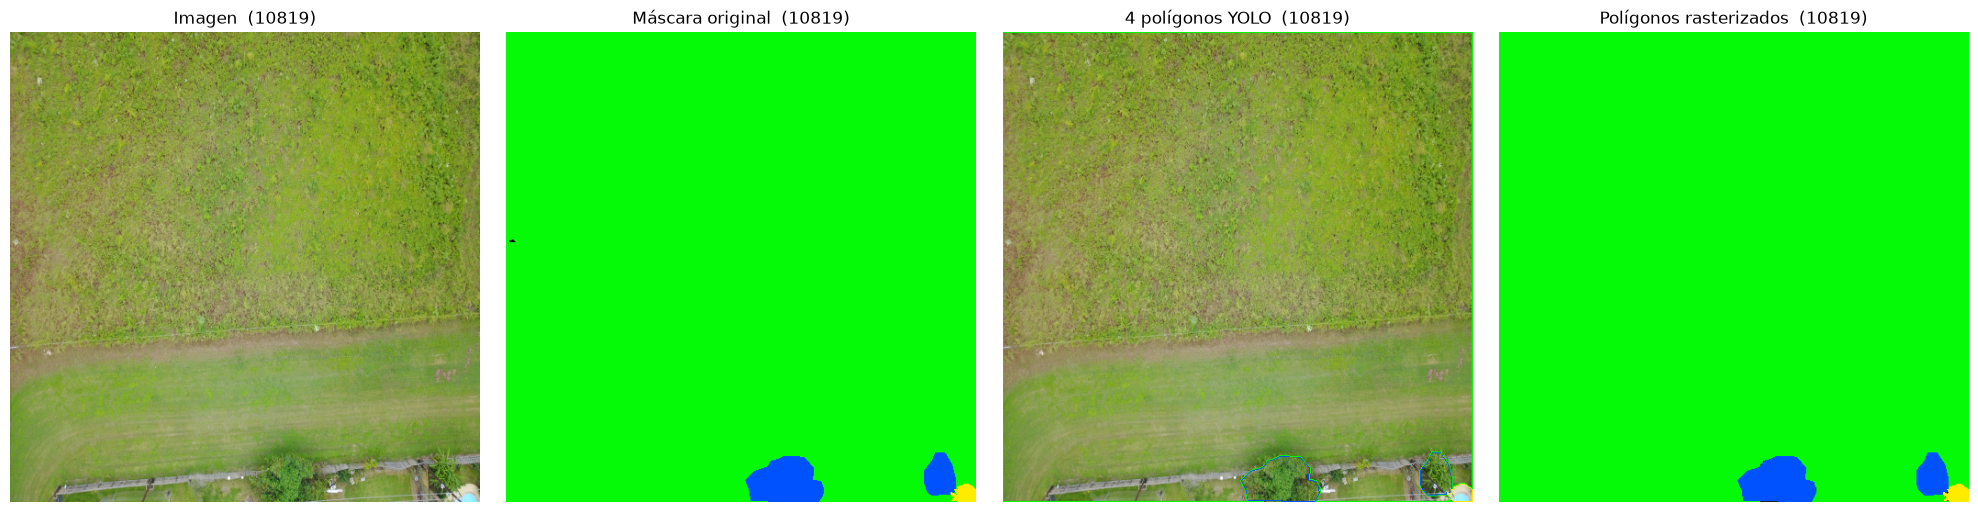

In [10]:
# Una imagen de test: máscara original frente a polígonos YOLO rasterizados.
stem = split_stems["test"][0]
img = cv2.cvtColor(cv2.imread(str(CACHE / "image" / f"{stem}.png")), cv2.COLOR_BGR2RGB)
gt = cv2.imread(str(CACHE / "mask" / f"{stem}.png"), cv2.IMREAD_GRAYSCALE)
polys = leer_etiquetas(YOLO_DIR / "labels" / "test" / f"{stem}.txt")

contornos = img.copy()
for c, p, _ in polys:
    cv2.polylines(contornos, [np.round(p).astype(np.int32)], True, PALETA[c].tolist(), 1)

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
for a, im, t in zip(ax, [img, colorear(gt), contornos, colorear(rasterizar(polys))],
                    ["Imagen", "Máscara original", f"{len(polys)} polígonos YOLO", "Polígonos rasterizados"]):
    a.imshow(im); a.set_title(f"{t}  ({stem})"); a.axis("off")
plt.tight_layout(); plt.show()

---
# 5. Entrenamiento

Se parte de `yolo11n-seg.pt` (preentrenado en COCO) y se entrena con los parámetros de la celda **P**.
Ultralytics elige el mejor checkpoint (`best.pt`) por su *fitness* en val, una combinación de mAP de
caja y de máscara. Los resultados se guardan en `runs/yolo/yolo11n-seg/`.

Con `workers = 4` la carga y la augmentación (mosaico incluido) van en paralelo y cada época tarda
unos 3 s, frente a unos 19 s con `workers = 0`. Ultralytics define su dataset en un módulo
importable, así que los workers por *spawn* de Windows funcionan también dentro de Jupyter. Si en
otra máquina se colgara, `workers = 0` es la alternativa segura.

In [11]:
from ultralytics import YOLO

RUN_DIR = PROJECT / "runs" / "yolo" / "yolo11n-seg"
BEST_PT = RUN_DIR / "weights" / "best.pt"

if ENTRENAR:
    model = YOLO(CONFIG["modelo_base"])
    model.train(
        data=str(DATA_YAML),
        imgsz=CONFIG["img_size"],
        epochs=CONFIG["epochs"],
        patience=CONFIG["patience"],
        batch=CONFIG["batch"],
        workers=CONFIG["workers"],
        optimizer=CONFIG["optimizer"],
        fliplr=CONFIG["fliplr"],
        flipud=CONFIG["flipud"],
        mosaic=CONFIG["mosaic"],
        overlap_mask=CONFIG["overlap_mask"],
        seed=CONFIG["seed"],
        deterministic=CONFIG["deterministic"],
        project=str(RUN_DIR.parent),
        name=RUN_DIR.name,
        exist_ok=True,
        device=0,
        verbose=False,
    )

assert BEST_PT.exists(), f"No existe {BEST_PT}: entrena con ENTRENAR = True"
model = YOLO(str(BEST_PT))
print("Checkpoint:", BEST_PT)

Ultralytics 8.4.177  Python-3.12.10 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\data\yolo512\floodnet.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n-seg, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True,

Overriding model.yaml nc=80 with nc=10



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.8it/s 0.5s

                   all         40        968      0.791      0.547      0.607      0.408      0.737      0.552      0.583      0.354


Speed: 0.5ms preprocess, 3.1ms inference, 0.0ms loss, 2.7ms postprocess per image


Results saved to C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\runs\yolo\yolo11n-seg


Checkpoint: C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\runs\yolo\yolo11n-seg\weights\best.pt


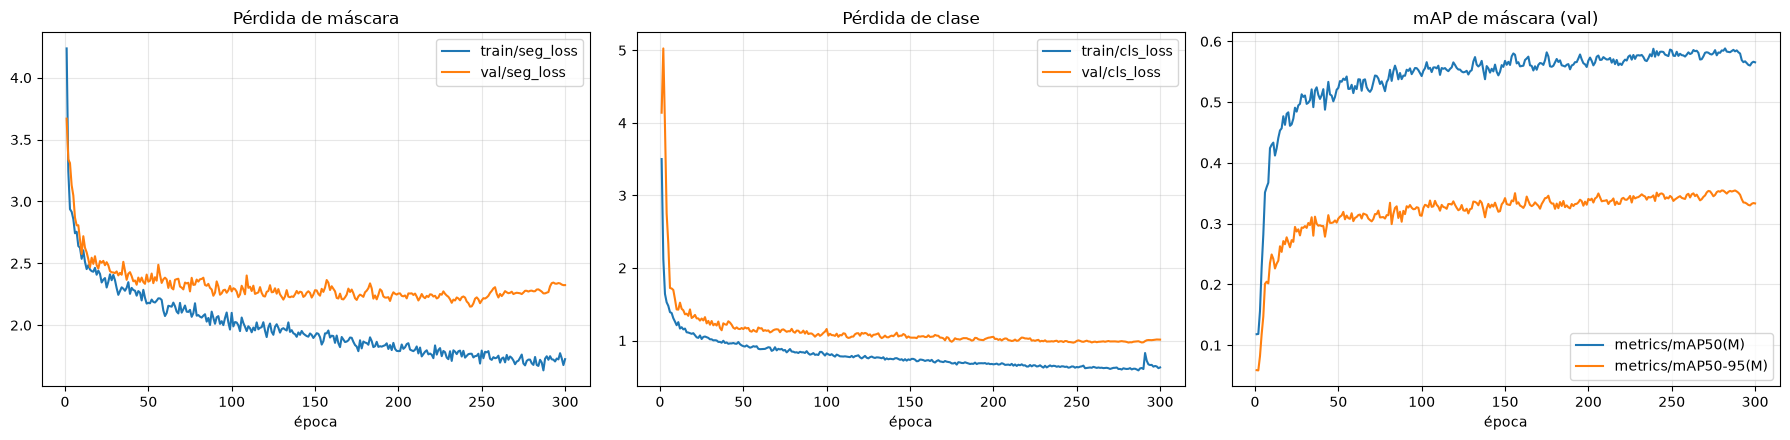

Épocas ejecutadas: 300


In [12]:
hist = pd.read_csv(RUN_DIR / "results.csv")
hist.columns = [c.strip() for c in hist.columns]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for col in ("train/seg_loss", "val/seg_loss"):
    ax[0].plot(hist["epoch"], hist[col], label=col)
for col in ("train/cls_loss", "val/cls_loss"):
    ax[1].plot(hist["epoch"], hist[col], label=col)
for col in ("metrics/mAP50(M)", "metrics/mAP50-95(M)"):
    ax[2].plot(hist["epoch"], hist[col], label=col)
for a, t in zip(ax, ["Pérdida de máscara", "Pérdida de clase", "mAP de máscara (val)"]):
    a.set_title(t); a.set_xlabel("época"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"Épocas ejecutadas: {len(hist)}")

---
# 6. Evaluación

### 6.1 mAP de instancias (métrica nativa de YOLO)

Es la métrica para la que YOLO está optimizado, calculada sobre las "instancias" artificiales de la
sección 3. **No es comparable con el mIoU del U-Net.** Se informa solo como referencia.

In [13]:
val_test = model.val(data=str(DATA_YAML), split="test", imgsz=SIZE, batch=CONFIG["batch"],
                     device=0, plots=False, verbose=False)
map_test = {
    "box_mAP50": float(val_test.box.map50), "box_mAP50_95": float(val_test.box.map),
    "mask_mAP50": float(val_test.seg.map50), "mask_mAP50_95": float(val_test.seg.map),
}
print(json.dumps(map_test, indent=2))
pd.DataFrame({"Clase": [class_names[i] for i in val_test.seg.ap_class_index],
              "mask AP50-95": np.round(val_test.seg.maps[val_test.seg.ap_class_index], 3)})

Ultralytics 8.4.177  Python-3.12.10 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)


YOLO11n-seg summary (fused): 114 layers, 2,851,654 parameters, 0 gradients, 9.7 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 55.8±2.1 MB/s, size: 507.0 KB)


val: Scanning C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\data\yolo512\labels\test... 30 images, 0 backgrounds, 0 corrupt: 73% ━━━━━━━━╸─── 30/41 84.2it/s 0.1s<0.1s

val: Scanning C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\data\yolo512\labels\test... 41 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 41/41 383.8it/s 0.1s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.7s/it 5.2s

                   all         41       1277      0.602      0.467      0.492      0.307      0.641      0.432      0.463      0.259


Speed: 1.6ms preprocess, 10.5ms inference, 0.0ms loss, 1.5ms postprocess per image


{
  "box_mAP50": 0.4919694555497937,
  "box_mAP50_95": 0.3074293170829908,
  "mask_mAP50": 0.46331989937304874,
  "mask_mAP50_95": 0.25947014315946726
}


,Clase,mask AP50-95
0,Background,0.006
1,Building-flooded,0.665
2,Building-non-flooded,0.335
3,Road-flooded,0.060
4,Road-non-flooded,0.156
5,Water,0.450
6,Tree,0.277
7,Vehicle,0.151
8,Pool,0.355
9,Grass,0.140


### 6.2 mIoU semántico: la comparación justa con el U-Net

Para cada imagen:

1. `predict` con `retina_masks=True`, que devuelve las máscaras a 512×512 en vez de a 128×128.
2. Las instancias se pintan en un mapa vacío **de mayor a menor área**, la misma regla que en
   entrenamiento.
3. Los píxeles que no cubre ninguna instancia quedan como *void* y cuentan como error de su clase
   real.

El umbral de confianza importa: si es bajo aparecen más falsos positivos y si es alto queda más *void*.
Se elige **en val** entre los candidatos de `CONFIG` y se aplica **una sola vez** en test.

In [14]:
def mapa_semantico(r):
    # Resultado de Ultralytics -> mapa de etiquetas (SIZE, SIZE); NUM_CLASSES = void.
    lab = np.full((SIZE, SIZE), NUM_CLASSES, dtype=np.uint8)
    if r.masks is None or len(r.masks) == 0:
        return lab
    m = r.masks.data.cpu().numpy() > 0.5
    if m.shape[1:] != (SIZE, SIZE):
        m = np.stack([cv2.resize(x.astype(np.uint8), (SIZE, SIZE),
                                 interpolation=cv2.INTER_NEAREST) > 0 for x in m])
    cls = r.boxes.cls.cpu().numpy().astype(int)
    for i in np.argsort(-m.sum(axis=(1, 2)), kind="stable"):
        lab[m[i]] = cls[i]
    return lab

def predecir(modelo, ruta, conf):
    r = modelo.predict(ruta, imgsz=SIZE, conf=conf, iou=CONFIG["iou_nms"], max_det=CONFIG["max_det"],
                       retina_masks=True, device=0, verbose=False)[0]
    return mapa_semantico(r)

def evaluar_semantico(modelo, imgs, msks, conf, desc=""):
    met = SegMetrics(NUM_CLASSES)
    for ip, mp in tqdm(list(zip(imgs, msks)), desc=desc, leave=False):
        met.update_labels(predecir(modelo, ip, conf), cv2.imread(mp, cv2.IMREAD_GRAYSCALE))
    return met

barrido = []
for conf in CONFIG["conf_candidatos"]:
    met = evaluar_semantico(model, val_imgs, val_masks, conf, desc=f"val conf={conf}")
    miou, mdice, acc = met.summary()
    barrido.append({"conf": conf, "mIoU": miou, "mIoU_sin_bg": met.summary(ignore=(0,))[0],
                    "PixAcc": acc, "void %": 100 * met.void_fraction()})
barrido = pd.DataFrame(barrido).round(4)
CONF = float(barrido.loc[barrido["mIoU"].idxmax(), "conf"])
print("Umbral elegido en val:", CONF)
barrido

val conf=0.05:   0%|          | 0/40 [00:00<?, ?it/s]

val conf=0.1:   0%|          | 0/40 [00:00<?, ?it/s]

val conf=0.25:   0%|          | 0/40 [00:00<?, ?it/s]

val conf=0.4:   0%|          | 0/40 [00:00<?, ?it/s]

Umbral elegido en val: 0.4


,conf,mIoU,mIoU_sin_bg,PixAcc,void %
0,0.05,0.6276,0.6973,0.8884,1.1516
1,0.10,0.6408,0.7120,0.8877,1.5757
2,0.25,0.6602,0.7336,0.8941,2.7063
3,0.40,0.6622,0.7358,0.8886,3.8200


In [15]:
met_test = evaluar_semantico(model, test_imgs, test_masks, CONF, desc="test")
res_test, tabla_test = informe(met_test, f"TEST (41 imágenes) — YOLO11n-seg, conf={CONF}")
tabla_test.assign(**{"Techo conversión IoU": tabla_techo["IoU"]})

test:   0%|          | 0/41 [00:00<?, ?it/s]

== TEST (41 imágenes) — YOLO11n-seg, conf=0.4 ==
  mIoU  : 0.6783   (sin Background: 0.7379)
  Dice  : 0.7829   (sin Background: 0.8423)
  PixAcc: 0.8912
  Píxeles sin predicción (void): 4.73 %


,Clase,Dice,IoU,Techo conversión IoU
0,Background,0.248,0.142,0.919
1,Building-flooded,0.919,0.851,0.983
2,Building-non-flooded,0.887,0.797,0.989
3,Road-flooded,0.729,0.574,0.980
4,Road-non-flooded,0.812,0.684,0.986
5,Water,0.943,0.892,0.996
6,Tree,0.870,0.770,0.990
7,Vehicle,0.661,0.494,0.943
8,Pool,0.819,0.693,0.973
9,Grass,0.940,0.887,0.995


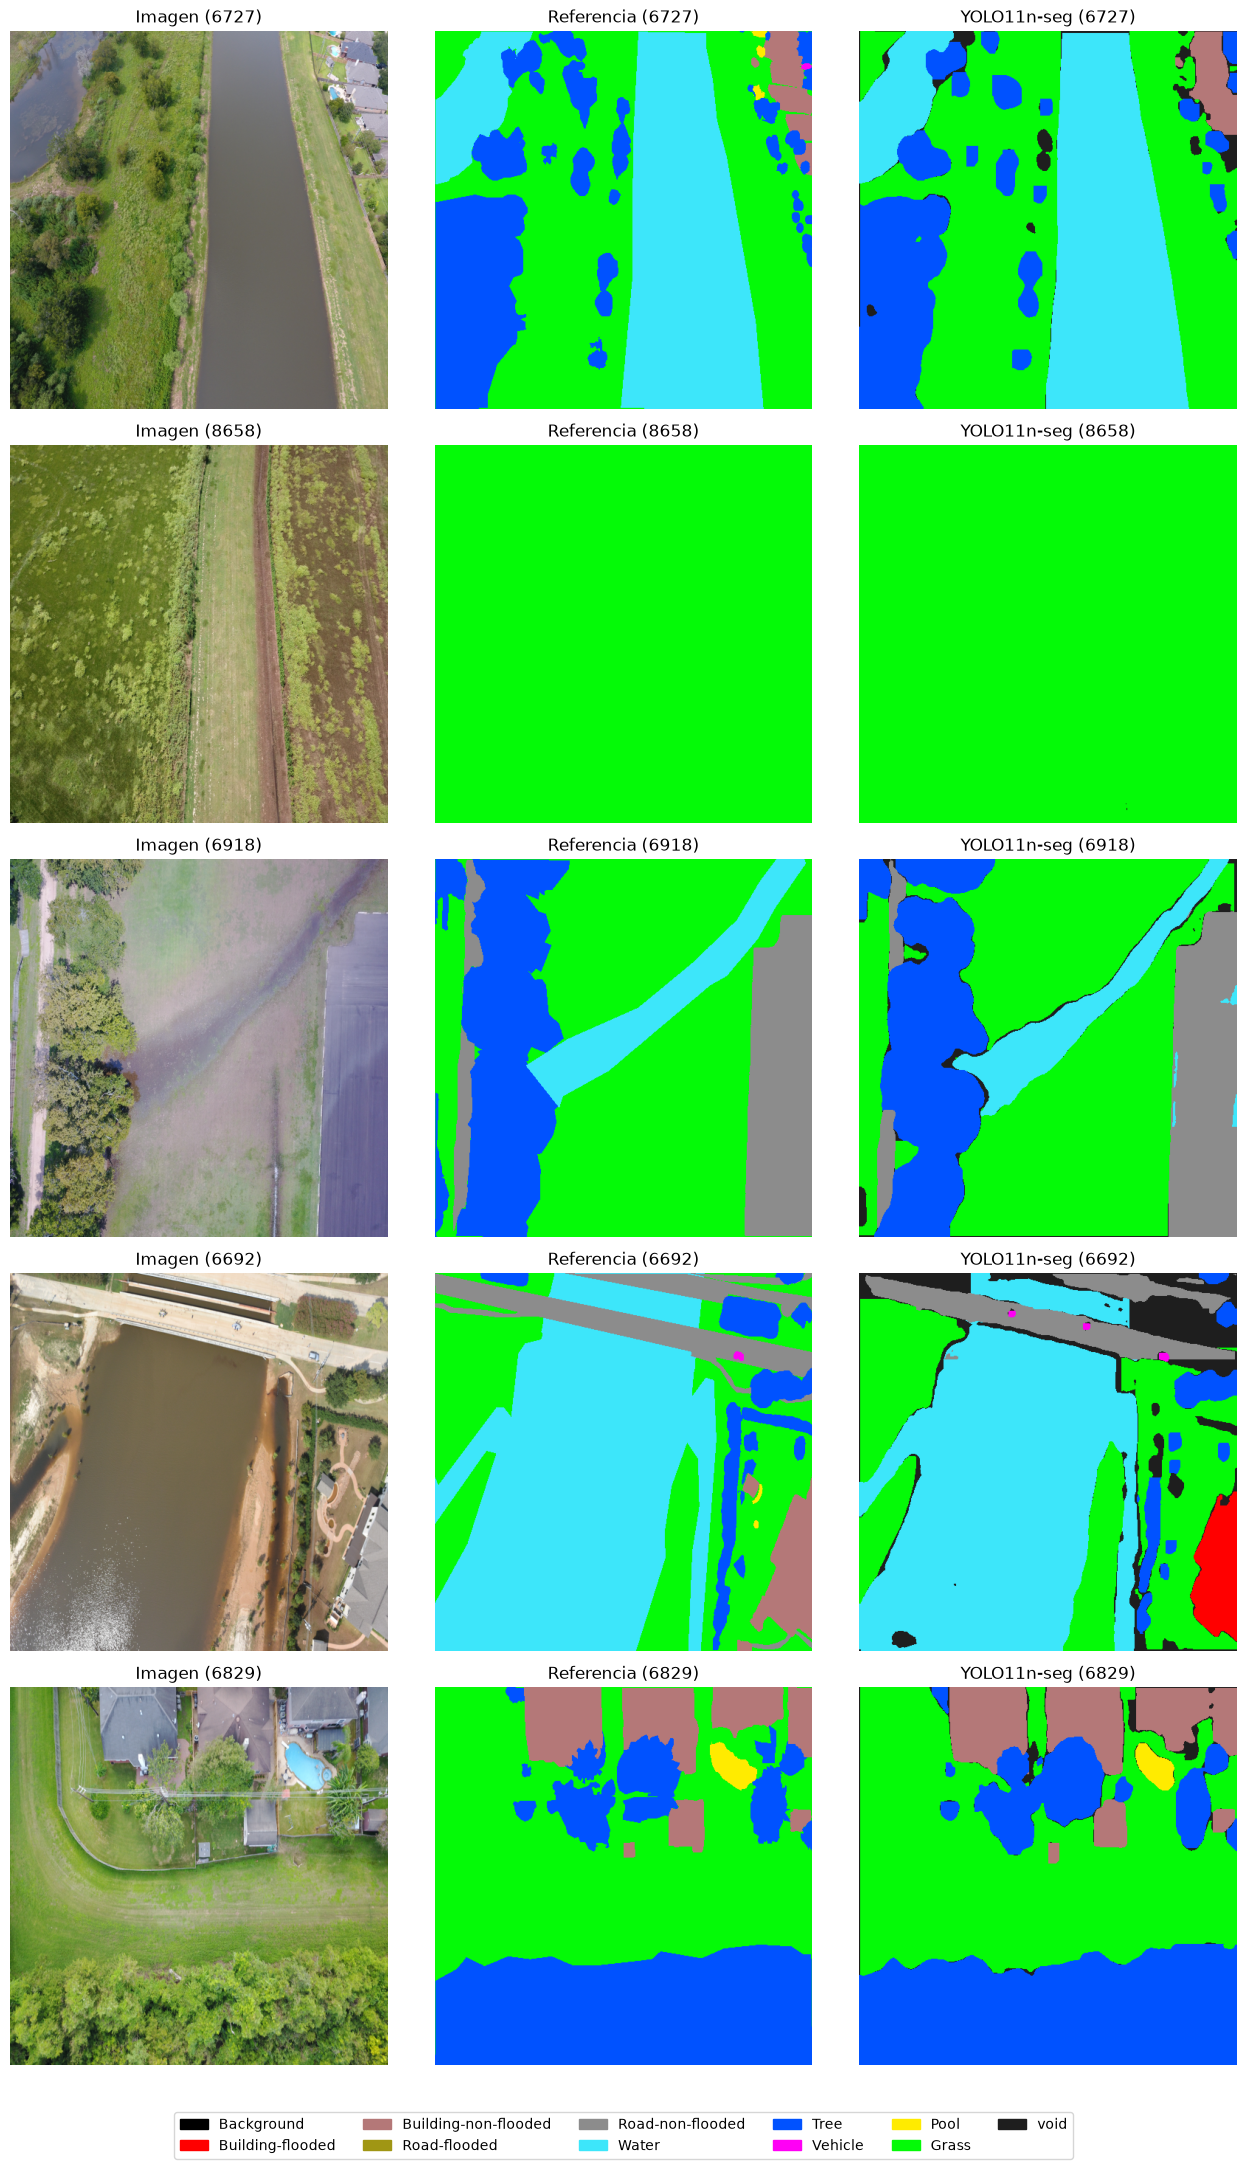

In [16]:
# Ejemplos de test: imagen, referencia y predicción (void en gris oscuro).
muestras = test_imgs[:5]
fig, ax = plt.subplots(len(muestras), 3, figsize=(13, 4.3 * len(muestras)))
for i, ip in enumerate(muestras):
    stem = Path(ip).stem
    img = cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB)
    gt = cv2.imread(test_masks[i], cv2.IMREAD_GRAYSCALE)
    pred = predecir(model, ip, CONF)
    for a, im, t in zip(ax[i], [img, colorear(gt), colorear(pred)], ["Imagen", "Referencia", "YOLO11n-seg"]):
        a.imshow(im); a.set_title(f"{t} ({stem})"); a.axis("off")

from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=PALETA[c] / 255, label=n) for c, n in enumerate(class_names + ["void"])],
           loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

---
# 7. Exportación a ONNX y verificación

Se exporta `best.pt` con entrada fija `1×3×512×512` en FP32 y se copia a
`models/yolo11n_seg_floodnet.onnx`.

**Qué hay dentro del grafo y qué no.** Este punto importa para medir el rendimiento:

| | ¿En el ONNX? |
|---|---|
| Backbone, neck y cabeza | Sí |
| `output0` 1×46×5376: caja xywh (4) + puntuación por clase (10) + coeficientes de máscara (32) | Sí |
| `output1` 1×32×128×128: prototipos de máscara | Sí |
| NMS, ensamblado de máscaras (coeficientes × prototipos, sigmoide, recorte, reescalado) | **No** |
| Repintado a mapa semántico | **No** |

Un benchmark que cronometre solo `session.run()` dejaría fuera una parte del trabajo que el
modelo semántico sí hace dentro del grafo, así que el post-proceso tiene que cronometrarse aparte.

**Preprocesado esperado**: RGB (no BGR), `float32` en [0, 1], NCHW. Como las imágenes ya miden 512×512
no hace falta *letterbox*.

La verificación carga el `.onnx` con Ultralytics, que lo ejecuta con ONNX Runtime, y repite la
evaluación semántica de test. El mIoU debe coincidir con el de PyTorch.

In [17]:
import onnx

ONNX_PATH = PROJECT / CONFIG["onnx_path"]
exportado = model.export(format="onnx", imgsz=SIZE, opset=CONFIG["onnx_opset"], simplify=True,
                         dynamic=False, half=False, device=0)
shutil.copy2(exportado, ONNX_PATH)

grafo = onnx.load(str(ONNX_PATH))
onnx.checker.check_model(grafo)
def _forma(v):
    return [d.dim_value or d.dim_param for d in v.type.tensor_type.shape.dim]
io_onnx = {"inputs":  {v.name: _forma(v) for v in grafo.graph.input},
           "outputs": {v.name: _forma(v) for v in grafo.graph.output}}
print(ONNX_PATH, f"({ONNX_PATH.stat().st_size / 2**20:.1f} MB)")
print(json.dumps(io_onnx, indent=2))

WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


Ultralytics 8.4.177  Python-3.12.10 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)


YOLO11n-seg summary (fused): 114 layers, 2,851,654 parameters, 0 gradients, 6.2 GFLOPs



PyTorch: starting from 'C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\runs\yolo\yolo11n-seg\weights\best.pt' with input shape (1, 3, 512, 512) BCHW and output shape(s) ((1, 46, 5376), (1, 32, 128, 128)) (5.8 MB)



ONNX: starting export with onnx 1.23.2 opset 17...


ONNX: slimming with onnxslim 0.1.98...


ONNX: export success  1.3s, saved as 'C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\runs\yolo\yolo11n-seg\weights\best.onnx' (11.1 MB)



Export complete (1.4s)
Results saved to C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\runs\yolo\yolo11n-seg\weights\best.onnx
Predict:         yolo predict task=segment model=C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\runs\yolo\yolo11n-seg\weights\best.onnx imgsz=512 
Validate:        yolo val task=segment model=C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\runs\yolo\yolo11n-seg\weights\best.onnx imgsz=512 data=C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\data\yolo512\floodnet.yaml  
Visualize:       https://netron.app


C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\models\yolo11n_seg_floodnet.onnx (11.1 MB)
{
  "inputs": {
    "images": [
      1,
      3,
      512,
      512
    ]
  },
  "outputs": {
    "output0": [
      1,
      46,
      5376
    ],
    "output1": [
      1,
      32,
      128,
      128
    ]
  }
}


In [18]:
import onnxruntime as ort

model_onnx = YOLO(str(ONNX_PATH), task="segment")
met_onnx = evaluar_semantico(model_onnx, test_imgs, test_masks, CONF, desc="test ONNX")
res_onnx, _ = informe(met_onnx, "TEST — ONNX Runtime")
print("\nProveedores ONNX Runtime disponibles:", ort.get_available_providers())

dif = abs(res_onnx["mIoU"] - res_test["mIoU"])
print(f"|mIoU ONNX - mIoU PyTorch| = {dif:.5f}")
assert dif < 0.005, "El ONNX no reproduce al modelo de PyTorch"

test ONNX:   0%|          | 0/41 [00:00<?, ?it/s]

Loading C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\models\yolo11n_seg_floodnet.onnx for ONNX Runtime inference...


Using ONNX Runtime 1.24.4 with CUDAExecutionProvider


== TEST — ONNX Runtime ==
  mIoU  : 0.6788   (sin Background: 0.7385)
  Dice  : 0.7833   (sin Background: 0.8427)
  PixAcc: 0.8915
  Píxeles sin predicción (void): 4.69 %

Proveedores ONNX Runtime disponibles: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
|mIoU ONNX - mIoU PyTorch| = 0.00056


### 7.1 Registro de parámetros y resultados

Todo lo necesario para reproducir y evaluar el modelo sale en un único JSON: configuración, lista
exacta de imágenes de cada partición, contrato de entrada/salida del ONNX y cifras obtenidas.

In [19]:
registro = {
    "config": CONFIG,
    "conf_elegido_en_val": CONF,
    "clases": class_names,
    "split_stems": split_stems,
    "onnx": {
        "path": CONFIG["onnx_path"],
        **io_onnx,
        "preprocesado": "RGB, float32 en [0,1], NCHW 1x3x512x512; imagen ya a 512, sin letterbox",
        "postprocesado_fuera_del_grafo": [
            f"filtrado por confianza (conf={CONF}) y NMS (iou={CONFIG['iou_nms']}, max_det={CONFIG['max_det']})",
            "máscara = sigmoid(coeficientes · prototipos 32x128x128), recorte a la caja, reescalado a 512, umbral 0.5",
            CONFIG["regla_repintado"],
        ],
    },
    "resultados": {
        "techo_conversion": res_techo,
        "val_barrido_conf": barrido.to_dict(orient="records"),
        "test_pytorch": res_test,
        "test_onnx": res_onnx,
        "test_por_clase": tabla_test.to_dict(orient="records"),
        "test_instancias": map_test,
        "epocas_ejecutadas": int(len(hist)),
    },
    "versiones": {"ultralytics": ultralytics.__version__, "torch": torch.__version__,
                  "onnx": onnx.__version__, "onnxruntime": ort.__version__},
}
(PROJECT / CONFIG["config_json"]).write_text(json.dumps(registro, indent=2, ensure_ascii=False, default=float),
                                              encoding="utf-8")
print("Guardado:", CONFIG["config_json"])

Guardado: models/yolo11n_seg_floodnet_config.json


---
# Conclusiones

Cifras de esta ejecución. Están también en `models/yolo11n_seg_floodnet_config.json`.

| | YOLO11n-seg | U-Net híbrido (README) |
|---|---:|---:|
| mIoU test (10 clases) | **0.678** | 0.714 |
| mIoU test (sin *Background*) | **0.738** | 0.777 |
| Dice test (10 clases) | 0.783 | 0.809 |
| Pixel accuracy | 0.891 | 0.927 |
| Píxeles sin predicción | 4.7 % | 0 % |
| TTA | no | sí (4 volteos) |
| Parámetros | 2.9 M | — |

| Clase | IoU YOLO | IoU U-Net | Techo conversión |
|---|---:|---:|---:|
| Building-flooded | 0.851 | 0.831 | 0.983 |
| Building-non-flooded | 0.797 | 0.803 | 0.989 |
| Water | 0.892 | 0.915 | 0.996 |
| Grass | 0.887 | 0.905 | 0.995 |
| Tree | 0.770 | 0.790 | 0.990 |
| Pool | 0.693 | 0.719 | 0.973 |
| Road-non-flooded | 0.684 | 0.777 | 0.986 |
| Road-flooded | 0.574 | 0.679 | 0.980 |
| Vehicle | 0.494 | 0.573 | 0.943 |
| Background | 0.142 | 0.144 | 0.919 |

Lecturas:

- **La conversión no es el cuello de botella.** Los polígonos reconstruyen las máscaras con mIoU
  0.976, así que lo que pierde YOLO frente al U-Net viene del modelo y no de las etiquetas.
- **YOLO aguanta mejor de lo esperado.** Con ~2.9 M de parámetros y sin TTA queda a ~4 puntos de mIoU
  del U-Net híbrido, y en *Building-flooded* lo supera. Los edificios son lo más parecido a
  "objetos" que tiene el dataset.
- **Donde más pierde es en las carreteras** (−9 / −10 puntos de IoU) **y en *Vehicle*** (−8). Las
  carreteras son regiones largas, finas y troceadas por árboles y coches: el peor caso para "una
  instancia = una componente conexa". Los vehículos ocupan pocos píxeles y sufren con las máscaras a
  1/4 de resolución.
- **El 4.7 % de píxeles queda sin cubrir** y cuenta como error. Es un coste estructural de usar
  instancias para un problema semántico.
- **El umbral elegido en val (0.40) es el mayor de los candidatos**, y las diferencias entre 0.25 y
  0.40 son mínimas (0.660 frente a 0.662). Un barrido más amplio quizá arañara algo, pero no
  cambiaría la conclusión.
- **Comparación justa con el U-Net**: aquí el U-Net cuenta con TTA de 4 volteos y YOLO con una sola
  pasada. Para el benchmark de rendimiento conviene medir los dos en las mismas condiciones y contar
  el post-proceso de YOLO (NMS, máscaras y repintado), que va fuera del ONNX.
